# Wstępna eksploracja 2018–2020: baseline (X) → publikacja (Y) → efekt po wejściu w życie (Z)

**Temat:** Ramowanie mediów a reakcja rynku na cła i sankcje · **Zespół:** B. Borkowski, I. Kowalczyk, M. Gadomski, P. Korus

Wstępna weryfikacja założeń Karty Eksploracji Danych (M1) na okresie wojny handlowej USA–Chiny **2018–2020**.
To nie jest pełny projekt — celem jest sprawdzenie, czy dane pozwalają zmierzyć zjawisko i czy wstępne sygnały wspierają hipotezę.

**Schemat pomiaru** (dla każdego aktu taryfowego, w sesjach giełdowych względem publikacji Y):

| okno | sesje | rola |
|---|---|---|
| **X — baseline** | Y−60 … Y−21 | „normalne” zachowanie rynku i natężenie narracji; z niego estymujemy średnią, zmienność i betę |
| **N — narracja przed Y** | Y−20 … Y−1 | okres kształtowania narracji (posty, media) przed formalną publikacją |
| **Y — publikacja** | Y … Y+1 | publikacja aktu w Federal Register |
| **Z — wejście w życie** | Z … Z+1 | dzień, od którego obowiązują cła |
| **Z+ — efekt po** | Z+2 … Z+10 | reakcja po wejściu w życie |

Hipoteza w tym schemacie: **nadwyżkowa reakcja rynku (względem X) pojawia się w N/Y, a nie w Z/Z+**, oraz zależy od ramy
narracji w oknie N, a nie od jej płaskiego sentymentu.

| element | źródło | status |
|---|---|---|
| Y, Z | Federal Register API — akty USTR Section 301 (Chiny) | ✅ API (cache CSV) |
| narracja | `tweets.csv` (Twitter @realDonaldTrump, UTC) — ramowanie postów | ✅ lokalnie |
| rynek | yfinance: S&P 500, VIX, EURUSD, USD/CNY, FXI (dziennie) | ✅ |
| media | GDELT GKG / FNSPID | ⏳ poza zakresem notebooka (posty jako proxy narracji) |

`trump_posts_full.csv` (Truth Social) zaczyna się w 2022 r., więc tu nie jest używany.

In [1]:
import re, json, warnings, urllib.request, urllib.parse
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.formula.api as smf
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid"); plt.rcParams["figure.figsize"] = (13, 4.5)
START, END = "2018-01-01", "2020-12-31"
DATA = Path(".")

## 1. Narracja — tweety 2018–2020

In [2]:
tw = pd.read_csv(DATA / "tweets.csv")
tw["ts_utc"] = pd.to_datetime(tw["date"], utc=True)
tw = tw[(tw.ts_utc >= START) & (tw.ts_utc < pd.Timestamp(END, tz="UTC") + pd.Timedelta(days=1))].copy()
tw["text"] = tw["text"].astype(str).str.replace("&amp;", "&", regex=False)
tw["is_repost"] = tw["isRetweet"].eq("t") | tw["text"].str.startswith("RT @")
tw["ts_et"] = tw["ts_utc"].dt.tz_convert("America/New_York")
x = tw[~tw.is_repost].copy()
print(f"Wszystkie tweety 2018–2020: {len(tw):,} | oryginalne: {len(x):,} | usunięte: {tw.isDeleted.eq('t').sum()}")

Wszystkie tweety 2018–2020: 23,622 | oryginalne: 14,193 | usunięte: 970


In [3]:
TOPIC = {
    "cła":     r"\btariff|\bdut(?:y|ies) on\b|import tax",
    "sankcje": r"\bsanction|\bembargo",
    "handel":  r"trade (?:war|deal|deficit|agreement|talks|imbalance)|\bunfair trade|\bUSMCA\b|\bNAFTA\b",
}
FRAME = {  # wymiary ramowania (multi-label)
    "eskalacja":   r"\bimpos|\braise|\braising|\bincreas|\bhike|\bretaliat|\bpunish|\bslap|\breciprocal|\bdouble|\bwill (?:be )?charg|\bthreat|\bsevere",
    "deeskalacja": r"\bdeal\b|\bnegotiat|\bagree(?:d|ment)|\bpause|\bsuspend|\bdelay|\blower(?:ed|ing)?\b|\breduc|\btalks\b|\btruce|\bexempt|\bremov|\bpostpon",
    "korzyść":     r"\bbillions?\b|\brevenue|\bjobs\b|\bfactor(?:y|ies)|\btreasury|\bpouring in|\bcollect",
    "krzywda":     r"ripped off|\bunfair|\babus|taken advantage|\bcheat|\bsteal|\bdecades\b",
    "konkret":     r"\d+(?:\.\d+)?\s?%|\$\s?\d+\s?(?:billion|b\b)|\bbillion dollars\b|\b(?:january|february|march|april|may|june|july|august|september|october|november|december) \d{1,2}",
}
COUNTRY = {"Chiny": r"\bchin(?:a|ese)\b|\bxi\b", "Meksyk": r"\bmexic", "Kanada": r"\bcanad", "UE": r"\beuropean union\b|\bE\.U\.|\beurope",
           "Iran": r"\biran\b", "Turcja": r"\bturkey\b", "Japonia": r"\bjapan", "Rosja": r"\brussia"}
flags = lambda s, P: pd.DataFrame({k: s.str.contains(p, case=False, regex=True) for k, p in P.items()}, index=s.index)

x = x.join(flags(x.text, TOPIC).add_prefix("t_"))
x["trade"] = x[["t_cła", "t_sankcje", "t_handel"]].any(axis=1)
vader = SentimentIntensityAnalyzer()
x["vader"] = x.text.map(lambda s: vader.polarity_scores(s)["compound"])
xt = x[x.trade].join(flags(x.loc[x.trade, "text"], FRAME).add_prefix("f_")).join(flags(x.loc[x.trade, "text"], COUNTRY).add_prefix("c_"))
xt["china_tariff"] = xt.c_Chiny & xt["t_cła"]
print("Tweety handlowe/celne/sankcyjne:", len(xt), "| w tym cła + Chiny:", xt.china_tariff.sum())
xt[[c for c in xt if c[:2] in ("t_", "f_", "c_")]].sum().to_frame("liczba").T

Tweety handlowe/celne/sankcyjne: 388 | w tym cła + Chiny: 85


,t_cła,t_sankcje,t_handel,f_eskalacja,f_deeskalacja,f_korzyść,f_krzywda,f_konkret,c_Chiny,c_Meksyk,c_Kanada,c_UE,c_Iran,c_Turcja,c_Japonia,c_Rosja
liczba,186,29,196,39,162,104,39,78,125,51,32,19,14,7,7,4


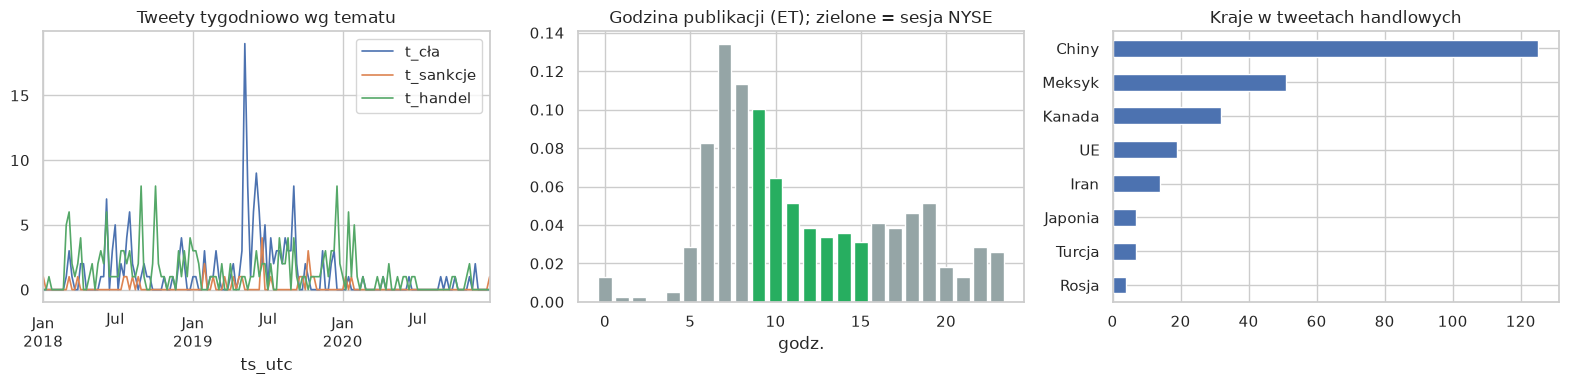

Tweety w trakcie sesji: 26%


In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
w = xt.set_index("ts_utc").resample("W")[["t_cła", "t_sankcje", "t_handel"]].sum()
w.plot(ax=axes[0], lw=1.2, title="Tweety tygodniowo wg tematu")
h = xt.ts_et.dt.hour.value_counts().sort_index() / len(xt)
axes[1].bar(h.index, h.values, color=["#27ae60" if 9 <= i < 16 else "#95a5a6" for i in h.index])
axes[1].set(title="Godzina publikacji (ET); zielone = sesja NYSE", xlabel="godz.")
xt[[c for c in xt if c.startswith("c_")]].sum().rename(lambda s: s[2:]).sort_values().plot.barh(ax=axes[2], title="Kraje w tweetach handlowych")
plt.tight_layout(); plt.show()
in_session = xt.ts_et.dt.hour.between(9, 15) & xt.ts_et.dt.dayofweek.lt(5)
print(f"Tweety w trakcie sesji: {in_session.mean():.0%}")

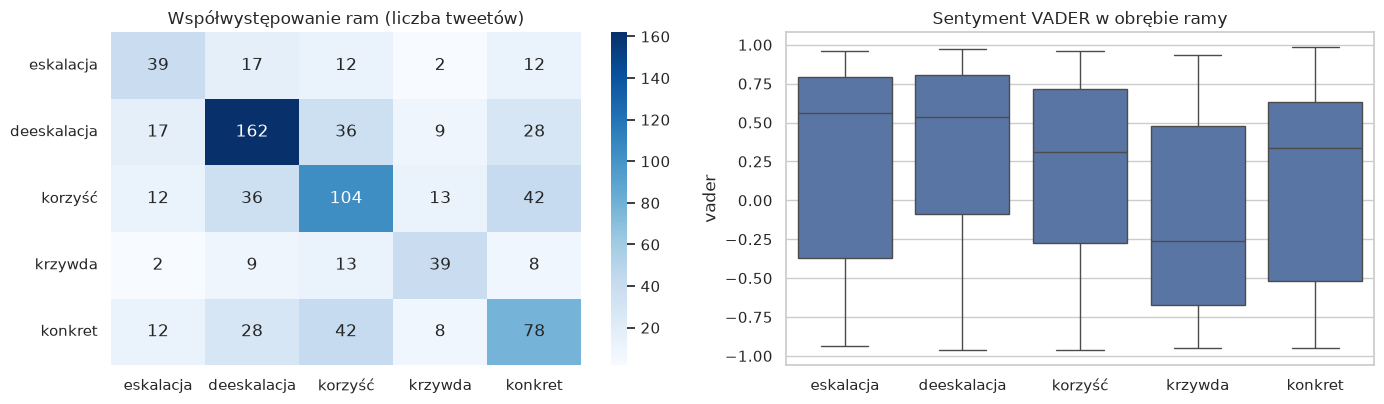

Korelacja ram z VADER (punktowo-biserialna):
eskalacja     -0.011
deeskalacja    0.144
korzyść       -0.055
krzywda       -0.181
konkret       -0.072


In [5]:
# współwystępowanie wymiarów ramowania i ich relacja z płaskim sentymentem
F = xt[[c for c in xt if c.startswith("f_")]].rename(columns=lambda s: s[2:]).astype(int)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
sns.heatmap(F.T @ F, annot=True, fmt="d", cmap="Blues", ax=axes[0]); axes[0].set_title("Współwystępowanie ram (liczba tweetów)")
sns.boxplot(data=F.assign(vader=xt.vader).melt(id_vars="vader").query("value == 1"), x="variable", y="vader", ax=axes[1])
axes[1].set(title="Sentyment VADER w obrębie ramy", xlabel="")
plt.tight_layout(); plt.show()
print("Korelacja ram z VADER (punktowo-biserialna):")
print(F.apply(lambda c: stats.pointbiserialr(c, xt.vader)[0]).round(3).to_string())

Ramy **eskalacji** i pozostałe mają podobny rozkład sentymentu VADER — płaski sentyment nie odróżnia
„grożę cłem 25%” od „mamy świetną umowę”. To uzasadnia wielowymiarowe ramowanie zamiast samego tonu.

## 2. Y i Z — akty Section 301 (Chiny) w Federal Register

In [6]:
FR_CACHE = DATA / "fr_section301_2018_2020.csv"
if FR_CACHE.exists():
    fr = pd.read_csv(FR_CACHE)
else:
    rows = []
    for page in (1, 2, 3):
        q = [("per_page", 100), ("page", page), ("conditions[term]", "section 301 china"),
             ("conditions[agencies][]", "trade-representative-office-of-united-states"),
             ("conditions[publication_date][gte]", START), ("conditions[publication_date][lte]", END)]
        q += [("fields[]", f) for f in ["title", "publication_date", "effective_on", "dates", "document_number", "html_url", "type"]]
        url = "https://www.federalregister.gov/api/v1/documents.json?" + urllib.parse.urlencode(q)
        res = json.load(urllib.request.urlopen(url, timeout=30))
        rows += res["results"]
        if page >= res.get("total_pages", 1): break
    fr = pd.DataFrame(rows); fr.to_csv(FR_CACHE, index=False)
print("Dokumenty USTR 'section 301 china':", len(fr))
fr["kategoria"] = np.select(
    [fr.title.str.contains("Exclusion", case=False), fr.title.str.contains("Request for Comments|Hearing|Procedures|Collection", case=False),
     fr.title.str.contains(r"^(?:Notice of Action|Notice of Modification)", case=False) & fr.title.str.contains("China")],
    ["wyłączenia produktów", "konsultacje/procedury", "AKT TARYFOWY"], "inne")
fr.kategoria.value_counts()

Dokumenty USTR 'section 301 china': 115


kategoria
wyłączenia produktów     90
AKT TARYFOWY             10
konsultacje/procedury     9
inne                      6
Name: count, dtype: int64

In [7]:
MONTHS = "January|February|March|April|May|June|July|August|September|October|November|December"
def parse_z(row):
    if isinstance(row.effective_on, str) and row.effective_on:
        return pd.Timestamp(row.effective_on)
    m = re.search(rf"(?:on or after|on|as of|time on|effective date of)\s+({MONTHS}) (\d{{1,2}}), (\d{{4}})", str(row.dates))
    if not m:
        m = re.search(rf"^({MONTHS}) (\d{{1,2}}), (\d{{4}})", str(row.dates))
    return pd.to_datetime(" ".join(m.groups())) if m else pd.NaT

# Kierunek aktu — ręczna klasyfikacja na podstawie treści (pole `dates` + tytuł):
KIERUNEK = {
    "2018-06-20": ("eskalacja",   "Lista 1: 25% na $34 mld"),
    "2018-08-16": ("eskalacja",   "Lista 2: 25% na $16 mld"),
    "2018-09-21": ("eskalacja",   "Lista 3: 10% na $200 mld"),
    "2018-12-19": ("deeskalacja", "odroczenie podwyżki do 25% (rozejm G20) na 2.03.2019"),
    "2019-03-05": ("deeskalacja", "Lista 3 pozostaje na 10% do odwołania"),
    "2019-05-09": ("eskalacja",   "Lista 3: podwyżka 10% → 25%"),
    "2019-08-20": ("eskalacja",   "Lista 4A/4B: 10% na $300 mld"),
    "2019-08-30": ("eskalacja",   "Lista 4A/4B: 10% → 15%"),
    "2019-12-18": ("deeskalacja", "zawieszenie Listy 4B (Phase One)"),
    "2020-01-22": ("deeskalacja", "Lista 4A: 15% → 7,5% (Phase One)"),
}
acts = fr[fr.kategoria == "AKT TARYFOWY"].copy()
acts["Y"] = pd.to_datetime(acts.publication_date)
acts["Z"] = acts.apply(parse_z, axis=1)
acts["kierunek"] = acts.publication_date.map(lambda d: KIERUNEK.get(d, ("?", ""))[0])
acts["akt"] = acts.publication_date.map(lambda d: KIERUNEK.get(d, ("?", ""))[1])
acts["Y_do_Z_dni"] = (acts.Z - acts.Y).dt.days
acts["status"] = np.select([acts.Z.isna(), acts.Z < acts.Y], ["BRAK DATY Z", "ROZJAZD (Z<Y)"], "OK")
acts = acts.sort_values("Y").reset_index(drop=True)
acts[["Y", "Z", "Y_do_Z_dni", "status", "kierunek", "akt"]]

,Y,Z,Y_do_Z_dni,status,kierunek,akt
0,2018-06-20,2018-07-06,16.0,OK,eskalacja,Lista 1: 25% na $34 mld
1,2018-08-16,2018-08-23,7.0,OK,eskalacja,Lista 2: 25% na $16 mld
2,2018-09-21,2018-09-24,3.0,OK,eskalacja,Lista 3: 10% na $200 mld
3,2018-12-19,NaT,NaN,BRAK DATY Z,deeskalacja,odroczenie podwyżki do 25% (rozejm G20) na 2.03.2019
4,2019-03-05,NaT,NaN,BRAK DATY Z,deeskalacja,Lista 3 pozostaje na 10% do odwołania
5,2019-05-09,2019-05-10,1.0,OK,eskalacja,Lista 3: podwyżka 10% → 25%
6,2019-08-20,2019-09-01,12.0,OK,eskalacja,Lista 4A/4B: 10% na $300 mld
7,2019-08-30,2019-09-01,2.0,OK,eskalacja,Lista 4A/4B: 10% → 15%
8,2019-12-18,2019-12-15,-3.0,ROZJAZD (Z<Y),deeskalacja,zawieszenie Listy 4B (Phase One)
9,2020-01-22,2020-02-14,23.0,OK,deeskalacja,"Lista 4A: 15% → 7,5% (Phase One)"


**Audyt dopasowania:** `ROZJAZD (Z<Y)` — akt opublikowany *po* dacie obowiązywania (zawieszenie ceł od 15.12.2019 opublikowane
18.12.2019; decyzję ogłoszono 13.12). `BRAK DATY Z` — akty odraczające („until further notice”, odroczenie podwyżki z 2.03.2019,
która ostatecznie nie weszła w życie). Te akty mają tylko okna X/N/Y. Daty Y z FR są **późniejsze** niż komunikaty USTR —
w pełnym projekcie właściwe Y da GTA.

## 3. Rynek i okna X / N / Y / Z / Z+

In [8]:
TICK = {"^GSPC": "SP500", "^VIX": "VIX", "EURUSD=X": "EURUSD", "CNY=X": "USDCNY", "FXI": "FXI"}
MC = DATA / "market_2018_2020.csv"
if MC.exists():
    mkt = pd.read_csv(MC, index_col=0, parse_dates=True)
else:
    import yfinance as yf
    mkt = pd.concat({n: yf.download(t, start="2017-11-01", end="2021-02-01", progress=False, threads=False, auto_adjust=True)["Close"].squeeze()
                     for t, n in TICK.items()}, axis=1)
    mkt.to_csv(MC)
mkt = mkt.dropna(subset=["SP500"]).ffill()
ret = np.log(mkt).diff().dropna().add_prefix("r_")
sessions = ret.index
COLS = ["r_SP500", "r_VIX", "r_EURUSD", "r_USDCNY", "r_FXI"]

def session_of(ts, cutoff_hour=16):
    # ts naive w czasie ET (dla dat kalendarzowych: północ). Po 16:00 ET → następna sesja.
    t = pd.Timestamp(ts)
    day = t.normalize() + (pd.Timedelta(days=1) if t.hour >= cutoff_hour else pd.Timedelta(0))
    i = sessions.searchsorted(day)
    return sessions[i] if i < len(sessions) else pd.NaT

acts["sY"] = acts.Y.map(session_of)                                   # FR publikuje ~8:45 ET → ta sama sesja
acts["sZ"] = acts.Z.map(lambda t: session_of(t) if pd.notna(t) else pd.NaT)   # cła od 00:01 ET → pierwsza sesja od Z
acts["iY"] = acts.sY.map(sessions.get_loc)
acts["iZ"] = acts.sZ.map(lambda s: sessions.get_loc(s) if pd.notna(s) else np.nan)
acts["Y_do_Z_sesji"] = acts.iZ - acts.iY
acts[["Y", "sY", "Z", "sZ", "Y_do_Z_sesji", "kierunek"]]

,Y,sY,Z,sZ,Y_do_Z_sesji,kierunek
0,2018-06-20,2018-06-20,2018-07-06,2018-07-06,11.0,eskalacja
1,2018-08-16,2018-08-16,2018-08-23,2018-08-23,5.0,eskalacja
2,2018-09-21,2018-09-21,2018-09-24,2018-09-24,1.0,eskalacja
3,2018-12-19,2018-12-19,NaT,NaT,NaN,deeskalacja
4,2019-03-05,2019-03-05,NaT,NaT,NaN,deeskalacja
5,2019-05-09,2019-05-09,2019-05-10,2019-05-10,1.0,eskalacja
6,2019-08-20,2019-08-20,2019-09-01,2019-09-03,9.0,eskalacja
7,2019-08-30,2019-08-30,2019-09-01,2019-09-03,1.0,eskalacja
8,2019-12-18,2019-12-18,2019-12-15,2019-12-16,-2.0,deeskalacja
9,2020-01-22,2020-01-22,2020-02-14,2020-02-14,17.0,deeskalacja


In [9]:
WINDOWS = {"X": ("Y", -60, -21), "N": ("Y", -20, -1), "Y": ("Y", 0, 1), "Z": ("Z", 0, 1), "Z+": ("Z", 2, 10)}
ORDER = list(WINDOWS)
# oczekiwany znak reakcji przy ESKALACJI (dla deeskalacji odwrotny): akcje ↓, VIX ↑, juan słabnie (USD/CNY ↑), FXI ↓
EXP_SIGN = {"r_SP500": -1, "r_VIX": +1, "r_USDCNY": +1, "r_FXI": -1, "r_EURUSD": np.nan}

def abnormal(e):
    # Model normalnych stóp zwrotu estymowany w oknie X: stała średnia; dla FXI model rynkowy względem S&P 500.
    base = ret.iloc[e.iY - 60:e.iY - 20]
    ar = ret[COLS] - base[COLS].mean()
    beta = base.r_FXI.cov(base.r_SP500) / base.r_SP500.var()
    alpha = base.r_FXI.mean() - beta * base.r_SP500.mean()
    ar["r_FXI"] = ret.r_FXI - (alpha + beta * ret.r_SP500)
    return ar, ar.iloc[e.iY - 60:e.iY - 20]

rows, paths = [], {}
for k, e in acts.iterrows():
    ar, ar_base = abnormal(e)
    sd, mabs = ar_base.std(), ar_base.abs().mean()
    sgn_dir = 1 if e.kierunek == "eskalacja" else -1
    paths[k] = ar
    for w, (anchor, a, b) in WINDOWS.items():
        i0 = e.iY if anchor == "Y" else e.iZ
        if pd.isna(i0): continue
        sl = ar.iloc[int(i0) + a:int(i0) + b + 1]; L = len(sl)
        for col in COLS:
            car = sl[col].sum(); scar = car / (sd[col] * np.sqrt(L))
            rows.append(dict(event=k, Y=e.Y.date(), kierunek=e.kierunek, status=e.status, okno=w, zmienna=col[2:], L=L,
                             CAR_pct=car * 100, SCAR=scar, SCAR_kier=scar * EXP_SIGN[col] * sgn_dir,
                             intensywnosc=sl[col].abs().mean() / mabs[col]))
R = pd.DataFrame(rows)
R["okno"] = pd.Categorical(R.okno, ORDER, ordered=True)
print("Zdarzeń:", R.event.nunique(), "| z oknem Z:", R[R.okno == "Z"].event.nunique())

Zdarzeń: 10 | z oknem Z: 8


**Miary** (wszystkie względem okna bazowego X danego zdarzenia):
- `SCAR` — standaryzowana skumulowana nadwyżkowa stopa zwrotu: CAR / (σ_X · √L); porównywalna między oknami różnej długości.
- `SCAR_kier` — SCAR ze znakiem „zgodnym z decyzją”: > 0 oznacza, że rynek poruszył się tak, jak sugeruje akt
  (przy eskalacji: S&P ↓, VIX ↑, USD/CNY ↑, FXI ↓; przy deeskalacji odwrotnie).
- `intensywnosc` — średnia |AR| w oknie / średnia |AR| w X (1 = norma; mierzy zmienność niezależnie od kierunku).

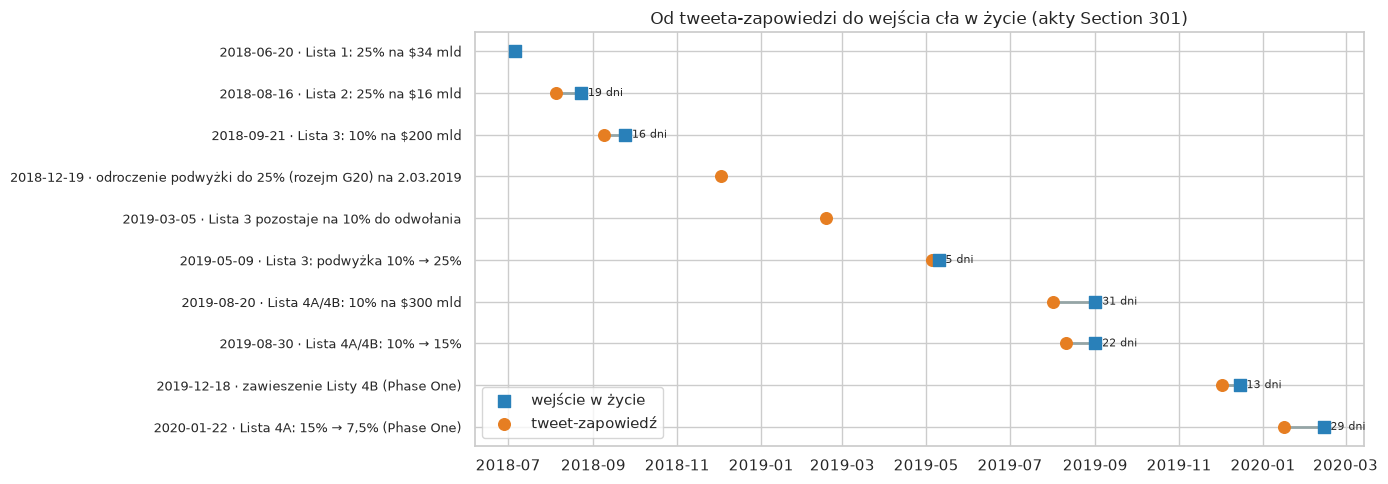

In [10]:
# Oś czasu: tweet-zapowiedź (pierwszy tweet sygnałowy o cłach na Chiny w oknie N) → wejście cła w życie (Z)
sig = xt[xt.china_tariff & (xt.f_konkret | xt.f_eskalacja | xt.f_deeskalacja)].assign(d=lambda df: df.ts_et.dt.tz_localize(None))
fig, ax = plt.subplots(figsize=(14, 5))
for i, (k, e) in enumerate(acts.iterrows()):
    first = sig[(sig.d >= sessions[int(e.iY) - 20]) & (sig.d <= e.sY + pd.Timedelta(hours=9))].d.min()
    if pd.notna(first) and pd.notna(e.Z):
        ax.plot([first, e.Z], [i, i], color="#95a5a6", lw=2, zorder=1)
        ax.text(max(first, e.Z) + pd.Timedelta(days=5), i, f"{(e.Z - first.normalize()).days} dni", va="center", fontsize=8)
    if pd.notna(first):
        ax.scatter(first, i, s=70, color="#e67e22", zorder=3, label="tweet-zapowiedź" if i == 0 or "tweet-zapowiedź" not in ax.get_legend_handles_labels()[1] else None)
    if pd.notna(e.Z):
        ax.scatter(e.Z, i, marker="s", s=70, color="#2980b9", zorder=3, label="wejście w życie" if "wejście w życie" not in ax.get_legend_handles_labels()[1] else None)
ax.set_yticks(range(len(acts))); ax.set_yticklabels([f"{e.Y:%Y-%m-%d} · {e.akt}" for _, e in acts.iterrows()], fontsize=9)
ax.invert_yaxis(); ax.legend(loc="lower left"); ax.set_title("Od tweeta-zapowiedzi do wejścia cła w życie (akty Section 301)")
plt.tight_layout(); plt.show()

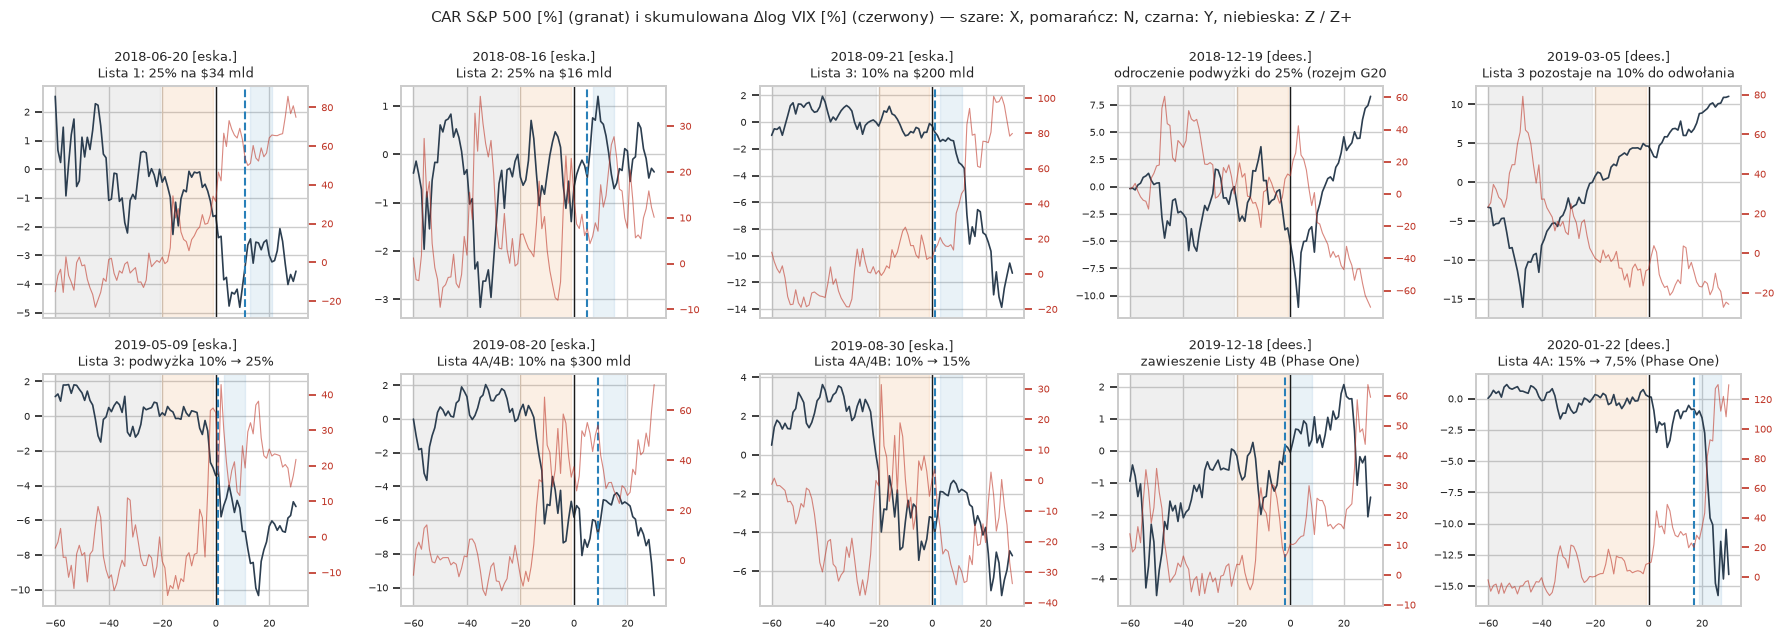

In [11]:
# Ścieżki skumulowanej AR S&P 500 i VIX dla każdego aktu, wyrównane do Y (0) z zaznaczonym Z
fig, axes = plt.subplots(2, 5, figsize=(18, 6.5), sharex=True)
for ax, (k, e) in zip(axes.flat, acts.iterrows()):
    ar = paths[k]
    rel = np.arange(-60, 31)
    seg = ar.iloc[e.iY - 60:e.iY + 31]
    ax.plot(rel[:len(seg)], seg.r_SP500.cumsum().values * 100, color="#2c3e50", lw=1.2, label="CAR S&P 500")
    ax2 = ax.twinx(); ax2.plot(rel[:len(seg)], seg.r_VIX.cumsum().values * 100, color="#c0392b", lw=.8, alpha=.6); ax2.grid(False)
    ax2.tick_params(labelsize=7, colors="#c0392b")
    ax.axvspan(-60, -21, color="grey", alpha=.12); ax.axvspan(-20, -1, color="#e67e22", alpha=.12)
    ax.axvline(0, color="k", lw=1)
    if pd.notna(e.iZ):
        z = e.iZ - e.iY; ax.axvline(z, color="#2980b9", lw=1.5, ls="--"); ax.axvspan(z + 2, z + 10, color="#2980b9", alpha=.1)
    ax.set_title(f"{e.Y:%Y-%m-%d} [{e.kierunek[:4]}.]\n{e.akt[:38]}", fontsize=9); ax.tick_params(labelsize=7)
fig.suptitle("CAR S&P 500 [%] (granat) i skumulowana Δlog VIX [%] (czerwony) — szare: X, pomarańcz: N, czarna: Y, niebieska: Z / Z+", fontsize=11)
plt.tight_layout(); plt.show()

## 4. Reakcja rynku w oknach — czy nadwyżka pojawia się przed Y, czy po Z?

In [12]:
summ = (R.groupby(["zmienna", "okno"], observed=True)
          .agg(n=("event", "nunique"), SCAR_kier_sr=("SCAR_kier", "mean"), SCAR_kier_med=("SCAR_kier", "median"),
               zgodnych=("SCAR_kier", lambda s: f"{(s > 0).sum()}/{s.notna().sum()}"), intensywnosc=("intensywnosc", "mean"))
          .reset_index())
summ["p_SCAR_kier"] = [stats.wilcoxon(g.SCAR_kier.dropna()).pvalue if g.SCAR_kier.notna().sum() >= 5 else np.nan
                       for _, g in R.groupby(["zmienna", "okno"], observed=True)]
summ["p_intens>1"] = [stats.wilcoxon(g.intensywnosc - 1, alternative="greater").pvalue if len(g) >= 5 else np.nan
                      for _, g in R.groupby(["zmienna", "okno"], observed=True)]
summ.round(3)

,zmienna,okno,n,SCAR_kier_sr,SCAR_kier_med,zgodnych,intensywnosc,p_SCAR_kier,p_intens>1
0,EURUSD,X,10,NaN,NaN,0/0,1.000,NaN,1.000
1,EURUSD,N,10,NaN,NaN,0/0,1.000,NaN,0.577
2,EURUSD,Y,10,NaN,NaN,0/0,0.875,NaN,0.839
3,EURUSD,Z,8,NaN,NaN,0/0,1.159,NaN,0.230
4,EURUSD,Z+,8,NaN,NaN,0/0,1.021,NaN,0.527
5,FXI,X,10,0.000,0.000,5/10,1.000,0.641,1.000
6,FXI,N,10,0.516,0.320,6/10,1.062,0.275,0.312
7,FXI,Y,10,0.087,-0.181,4/10,1.076,1.000,0.461
8,FXI,Z,8,-0.350,-0.186,4/8,1.104,0.641,0.191
9,FXI,Z+,8,0.763,0.438,6/8,1.225,0.148,0.680


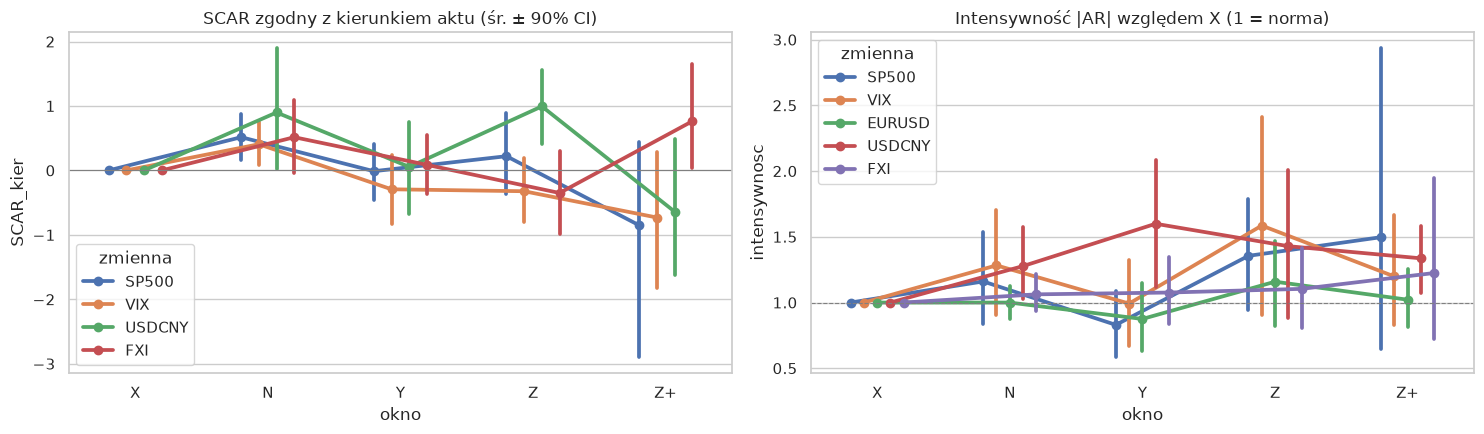

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
dirv = R[R.zmienna.isin(["SP500", "VIX", "USDCNY", "FXI"])]
sns.pointplot(data=dirv, x="okno", y="SCAR_kier", hue="zmienna", dodge=.4, errorbar=("ci", 90), ax=axes[0], markersize=5)
axes[0].axhline(0, color="grey", lw=.8); axes[0].set(title="SCAR zgodny z kierunkiem aktu (śr. ± 90% CI)", ylabel="SCAR_kier", xlabel="okno")
sns.pointplot(data=R, x="okno", y="intensywnosc", hue="zmienna", dodge=.4, errorbar=("ci", 90), ax=axes[1], markersize=5)
axes[1].axhline(1, color="grey", lw=.8, ls="--"); axes[1].set(title="Intensywność |AR| względem X (1 = norma)", xlabel="okno")
plt.tight_layout(); plt.show()

In [14]:
# Test główny hipotezy: reakcja „przed” (N+Y) vs „po” (Z+Z+), sparowana po zdarzeniach z oknem Z
def pre_post(R):
    rows = []
    for col in ["SP500", "VIX", "USDCNY", "FXI"]:
        g = R[R.zmienna == col]
        piv_s = g.pivot_table(index="event", columns="okno", values="SCAR_kier", observed=False)
        piv_i = g.pivot_table(index="event", columns="okno", values="intensywnosc", observed=False)
        both = piv_s.dropna(subset=["N", "Y", "Z", "Z+"]).index
        pre_s = (piv_s.loc[both, "N"] + piv_s.loc[both, "Y"]) / np.sqrt(2); post_s = (piv_s.loc[both, "Z"] + piv_s.loc[both, "Z+"]) / np.sqrt(2)
        pre_i = piv_i.loc[both, ["N", "Y"]].mean(axis=1); post_i = piv_i.loc[both, ["Z", "Z+"]].mean(axis=1)
        rows.append(dict(zmienna=col, n=len(both), SCAR_kier_przed=pre_s.mean(), SCAR_kier_po=post_s.mean(),
                         p_SCAR=stats.wilcoxon(pre_s, post_s).pvalue, intens_przed=pre_i.mean(), intens_po=post_i.mean(),
                         p_intens=stats.wilcoxon(pre_i, post_i).pvalue))
    return pd.DataFrame(rows)

print("Wszystkie zdarzenia z oknem Z:"); display(pre_post(R).round(3))
# Odporność: okno Z+ aktu z 22.01.2020 (Z = 14.02.2020 → Z+ = 19–28.02.2020) pokrywa się z początkiem krachu COVID
covid = acts.index[acts.Y == "2020-01-22"]
print("Bez aktu z 22.01.2020 (Z+ skażone krachem COVID):"); display(pre_post(R[~R.event.isin(covid)]).round(3))

Wszystkie zdarzenia z oknem Z:


,zmienna,n,SCAR_kier_przed,SCAR_kier_po,p_SCAR,intens_przed,intens_po,p_intens
0,SP500,8,0.615,-0.445,0.383,1.025,1.426,0.844
1,VIX,8,0.206,-0.745,0.250,1.243,1.392,0.945
2,USDCNY,8,0.895,0.252,0.641,1.609,1.383,0.383
3,FXI,8,0.368,0.292,0.844,1.082,1.164,0.547


Bez aktu z 22.01.2020 (Z+ skażone krachem COVID):


,zmienna,n,SCAR_kier_przed,SCAR_kier_po,p_SCAR,intens_przed,intens_po,p_intens
0,SP500,7,0.717,0.382,0.688,1.068,1.101,0.812
1,VIX,7,0.287,-0.314,0.469,1.355,1.284,0.469
2,USDCNY,7,1.089,0.432,0.812,1.565,1.424,0.688
3,FXI,7,0.530,-0.101,0.375,1.018,1.029,0.938


Próba jest mała (10 aktów, 8 z datą Z), a okna sąsiednich aktów częściowo się nakładają (np. 20.08 i 30.08.2019 mają wspólne Z = 1.09.2019;
okno bazowe X części aktów z 2019 r. zawiera wcześniejsze rundy). Wyniki są opisowe — testy Wilcoxona traktujemy orientacyjnie.

## 5. Narracja w oknach — czy posty „budują” decyzję przed Y?

In [15]:
x["sess"] = x.ts_et.dt.tz_localize(None).map(session_of)
xt["sess"] = x.loc[xt.index, "sess"]
FR_COLS = [c for c in xt if c.startswith("f_")]
nrows = []
for k, e in acts.iterrows():
    for w, (anchor, a, b) in WINDOWS.items():
        i0 = e.iY if anchor == "Y" else e.iZ
        if pd.isna(i0): continue
        lo, hi = sessions[int(i0) + a], sessions[min(int(i0) + b, len(sessions) - 1)]
        L = int(b - a + 1)
        allw = x[(x.sess >= lo) & (x.sess <= hi)]; tw_w = xt[(xt.sess >= lo) & (xt.sess <= hi)]
        d = dict(event=k, Y=e.Y.date(), kierunek=e.kierunek, okno=w, L=L,
                 posty_handl_na_sesje=len(tw_w) / L, chiny_cla_na_sesje=tw_w.china_tariff.sum() / L,
                 udzial_handl=len(tw_w) / max(1, len(allw)), vader=tw_w.vader.mean())
        for c in FR_COLS: d[c[2:]] = tw_w[c].mean() if len(tw_w) else np.nan
        d["net_frame"] = d["eskalacja"] - d["deeskalacja"] if len(tw_w) else np.nan
        nrows.append(d)
NR = pd.DataFrame(nrows); NR["okno"] = pd.Categorical(NR.okno, ORDER, ordered=True)
NR.groupby("okno", observed=True)[["posty_handl_na_sesje", "chiny_cla_na_sesje", "udzial_handl", "vader", "eskalacja", "deeskalacja", "konkret", "net_frame"]].mean().round(3)

,posty_handl_na_sesje,chiny_cla_na_sesje,udzial_handl,vader,eskalacja,deeskalacja,konkret,net_frame
okno,,,,,,,,
X,0.705,0.132,0.043,0.269,0.124,0.423,0.213,-0.299
N,0.760,0.205,0.047,0.261,0.105,0.454,0.218,-0.348
Y,1.400,0.450,0.059,0.208,0.034,0.500,0.071,-0.466
Z,3.312,1.000,0.094,0.371,0.008,0.462,0.045,-0.455
Z+,0.667,0.139,0.045,0.261,0.078,0.447,0.215,-0.369


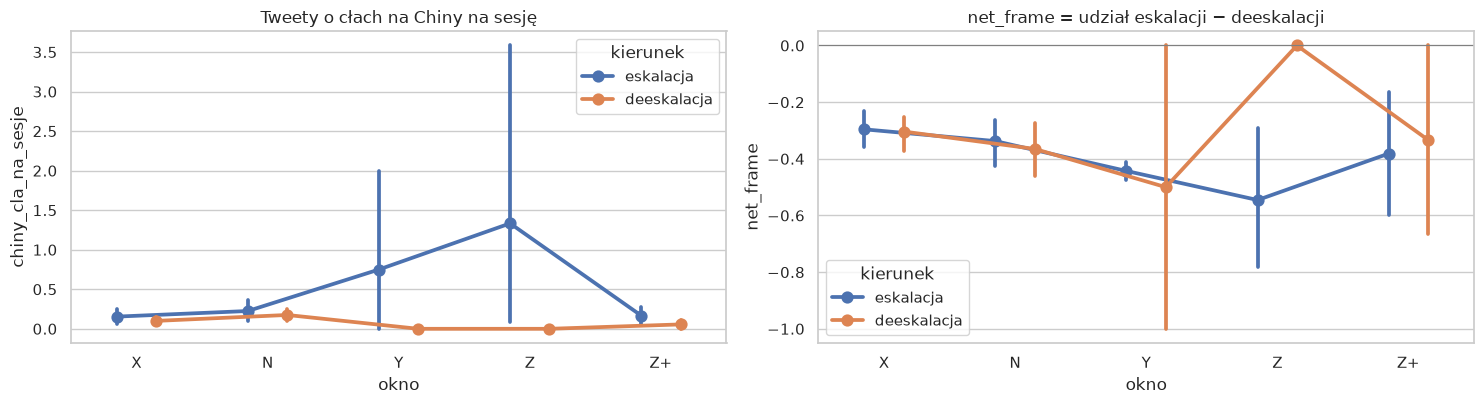

Tweety cła+Chiny na sesję: X = 0.133, N = 0.205  (Wilcoxon N > X: p = 0.057)


In [16]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.2))
sns.pointplot(data=NR, x="okno", y="chiny_cla_na_sesje", hue="kierunek", dodge=.3, errorbar=("ci", 90), ax=axes[0])
axes[0].set(title="Tweety o cłach na Chiny na sesję", xlabel="okno")
sns.pointplot(data=NR, x="okno", y="net_frame", hue="kierunek", dodge=.3, errorbar=("ci", 90), ax=axes[1])
axes[1].axhline(0, color="grey", lw=.8); axes[1].set(title="net_frame = udział eskalacji − deeskalacji", xlabel="okno")
plt.tight_layout(); plt.show()
w = NR.pivot_table(index="event", columns="okno", values="chiny_cla_na_sesje", observed=False)
print(f"Tweety cła+Chiny na sesję: X = {w.X.mean():.3f}, N = {w.N.mean():.3f}  (Wilcoxon N > X: p = {stats.wilcoxon(w.N - w.X, alternative='greater').pvalue:.3f})")

## 6. Rama vs płaski sentyment — przekrój zdarzeń (okno N)

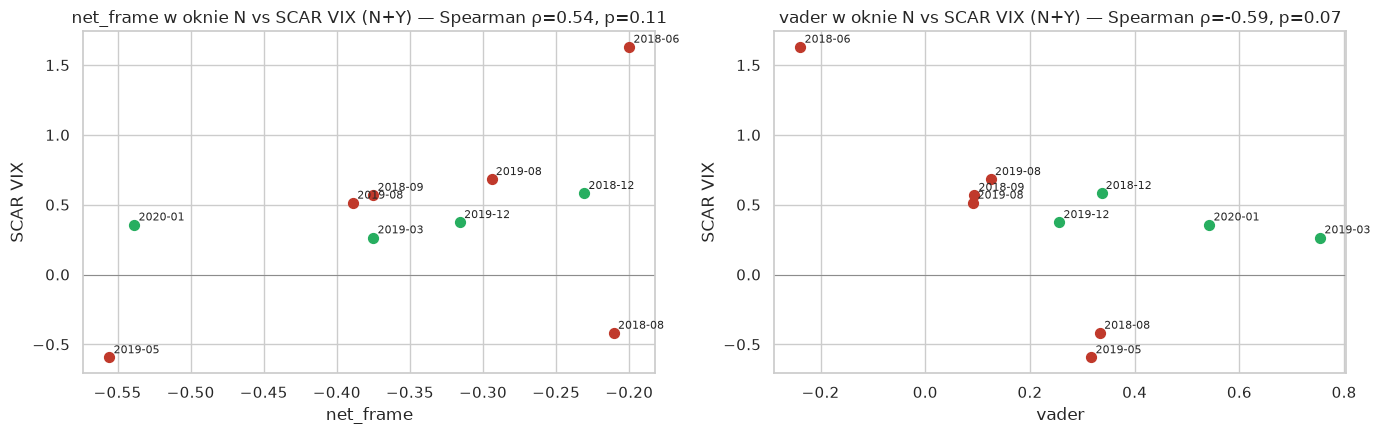

reakcja_NY,FXI,SP500,USDCNY,VIX
sygnał_N,,,,
chiny_cla_na_sesje,0.20,-0.61,0.48,0.15
konkret,-0.23,0.45,0.09,-0.43
net_frame,0.43,0.10,-0.30,0.54
vader,0.37,0.38,-0.19,-0.59


In [17]:
# Czy rama narracji w N (przed publikacją) wiąże się z reakcją rynku w N+Y, lepiej niż sentyment?
reac = R[R.okno.isin(["N", "Y"])].groupby(["event", "zmienna"]).SCAR.sum().unstack() / np.sqrt(2)
cross = NR[NR.okno == "N"].set_index("event")[["Y", "kierunek", "net_frame", "vader", "konkret", "chiny_cla_na_sesje"]].join(reac)
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
for ax, xv in zip(axes, ["net_frame", "vader"]):
    for _, r in cross.iterrows():
        ax.scatter(r[xv], r.VIX, color="#c0392b" if r.kierunek == "eskalacja" else "#27ae60", s=50)
        ax.annotate(str(r.Y)[:7], (r[xv], r.VIX), fontsize=8, xytext=(3, 3), textcoords="offset points")
    rho, p = stats.spearmanr(cross[xv], cross.VIX, nan_policy="omit")
    ax.set(title=f"{xv} w oknie N vs SCAR VIX (N+Y) — Spearman ρ={rho:.2f}, p={p:.2f}", xlabel=xv, ylabel="SCAR VIX")
    ax.axhline(0, color="grey", lw=.6)
plt.tight_layout(); plt.show()
tab = []
for xv in ["net_frame", "konkret", "chiny_cla_na_sesje", "vader"]:
    for yv in ["SP500", "VIX", "USDCNY", "FXI"]:
        rho, p = stats.spearmanr(cross[xv], cross[yv], nan_policy="omit"); tab.append(dict(sygnał_N=xv, reakcja_NY=yv, rho=rho, p=p))
pd.DataFrame(tab).pivot(index="sygnał_N", columns="reakcja_NY", values="rho").round(2)

## 7. Analiza pomocnicza (dzienna, cały okres 2018–2020)

Niezależnie od zdarzeń: czy dzienny wolumen / ton tweetów handlowych lub ich ramy wiążą się z |ΔVIX| następnej sesji
(test założenia „wolumen > ton” z eksploracji GDELT na poziomie postów).

In [18]:
day_all = x.groupby("sess").agg(n_all=("vader", "size"), tone_all=("vader", "mean"))
day_tr = x[x.trade].groupby("sess").agg(n_trade=("vader", "size"), tone_trade=("vader", "mean"))
D = ret.loc[START:END].join(day_all).join(day_tr)
D[["n_all", "n_trade"]] = D[["n_all", "n_trade"]].fillna(0)
D["delta_tone"] = D.tone_trade - D.tone_all.rolling(30, min_periods=10).mean()
D["abs_vix_next"] = D.r_VIX.abs().shift(-1); D["vix_next"] = D.r_VIX.shift(-1)
out = []
for a, b in [("n_trade", "abs_vix_next"), ("tone_trade", "abs_vix_next"), ("delta_tone", "abs_vix_next"), ("delta_tone", "vix_next")]:
    s = D[[a, b]].dropna(); rho, p = stats.spearmanr(s[a], s[b]); out.append(dict(sygnał=a, rynek=b, n=len(s), spearman=rho, p=p))
display(pd.DataFrame(out).round(4))

fr_day = xt.groupby("sess")[FR_COLS].max().astype(int).rename(columns=lambda c: c[2:]).rename(columns={"korzyść": "korzysc"})
M = D.join(fr_day, how="inner").dropna(subset=["tone_trade", "vix_next"])
res = []
for name, f in [("płaski sentyment", "abs_vix_next ~ tone_trade"),
                ("ramy", "abs_vix_next ~ eskalacja + deeskalacja + korzysc + krzywda + konkret"),
                ("ramy + sentyment", "abs_vix_next ~ tone_trade + eskalacja + deeskalacja + korzysc + krzywda + konkret")]:
    m = smf.ols(f, M).fit(cov_type="HC1"); res.append(dict(model=name, n=int(m.nobs), R2_adj=m.rsquared_adj, AIC=m.aic, p_F=m.f_pvalue))
pd.DataFrame(res).round(4)

,sygnał,rynek,n,spearman,p
0,n_trade,abs_vix_next,755,0.0229,0.5300
1,tone_trade,abs_vix_next,211,-0.0100,0.8847
2,delta_tone,abs_vix_next,210,-0.0070,0.9201
3,delta_tone,vix_next,210,0.0890,0.1991


,model,n,R2_adj,AIC,p_F
0,płaski sentyment,211,-0.0029,-582.3768,0.4867
1,ramy,211,-0.0077,-577.4617,0.3739
2,ramy + sentyment,211,-0.0109,-575.8131,0.4693


## 8. Wnioski wstępne

> Liczby z bieżącego uruchomienia (n = 10 aktów, 8 z datą Z) — wyniki opisowe, nie rozstrzygające.

**Wykonalność pomiaru: tak.** Z Federal Register (USTR, Section 301, Chiny) wyodrębniono 10 aktów taryfowych
(6 eskalacji, 4 deeskalacje); audyt: 7 × OK, 2 × BRAK DATY Z, 1 × ROZJAZD. Każdy akt ma okno bazowe X, z którego
estymujemy normalne stopy zwrotu, zmienność i betę FXI, oraz okna N/Y/Z/Z+. Mediana Y→Z to 3 sesje (od −2 do 17),
więc okna Y i Z często leżą blisko siebie — to ogranicza rozdzielenie efektów publikacji i wejścia w życie.

**Rynek reaguje przed publikacją (okno N), nie w dniu publikacji (Y).**
- W oknie N (20 sesji przed Y) S&P 500 poruszał się zgodnie z kierunkiem późniejszego aktu w **9 z 10** przypadków
  (śr. SCAR_kier = 0,52; Wilcoxon p = 0,037) — jedyny wynik istotny na poziomie 5%. Podobny, nieistotny kierunek dla
  USD/CNY (7/10), FXI i VIX (6/10).
- Sama publikacja (Y) nie niesie nowej informacji: SCAR_kier ≈ 0, intensywność S&P 500 **0,83×** normy.
- W Z juan reaguje zgodnie z aktem w **7/8** przypadków (p = 0,055) — kanał walutowy wycenia także faktyczne wejście w życie.
- Po Z (Z+) VIX i S&P 500 częściej odwracają ruch („sell the rumor, buy the fact”).

**Przed vs po — efekt słabszy, niż zakłada hipoteza.** Kierunkowa nadwyżka jest większa przed (N+Y) niż po (Z+Z+)
dla wszystkich czterech zmiennych, ale **żadna różnica nie jest istotna** (p ≥ 0,25). Intensywność zmienności po Z
nie jest niższa niż przed: bez aktu z 22.01.2020 (Z+ pokrywa się z krachem COVID) S&P 500 ma 1,07× normy przed i 1,10× po.
Uczciwie: na danych dziennych i przy n = 8 nie da się stwierdzić, że rynek wycenia decyzje *wyłącznie* na etapie narracji;
widać jedynie, że **kierunek** jest wyceniany przed publikacją.

**Narracja narasta przed Y.** Tweety o cłach na Chiny: 0,13 na sesję w X → 0,21 w N (p = 0,057) → 0,45 w Y → 1,0 w Z.
Rama w N jest głównie deeskalacyjna (net_frame ≈ −0,35) nawet przed aktami eskalacyjnymi; udział „konkretu” (stawki, kwoty, daty)
spada w Y i Z — konkret pojawia się wcześniej, w fazie zapowiedzi.

**Rama vs płaski sentyment — nierozstrzygnięte.** W przekroju 10 zdarzeń net_frame w N koreluje z reakcją VIX (ρ = 0,54),
ale sentyment VADER równie silnie (ρ = −0,59); przy n = 10 żadna korelacja nie jest istotna (próg |ρ| ≈ 0,64).
W analizie dziennej ani wolumen, ani ton, ani ramy tweetów nie wyjaśniają |ΔVIX| następnej sesji (R²_adj ≈ 0).
Teza o przewadze ramy nad sentymentem **nie znajduje na razie potwierdzenia w danych z postów** — wymaga GDELT (mediów)
i większej liczby zdarzeń.

### Kolejne kroki (pełny projekt)
1. **GTA** — daty ogłoszeń (komunikaty USTR / Białego Domu) jako właściwe Y; FR jest publikacją formalną, często kilka dni po ogłoszeniu.
2. **Więcej zdarzeń** — proklamacje Section 232 (stal/aluminium), IEEPA (Meksyk 2019), odwet Chin; dziś n = 10.
3. **GDELT GKG** — wolumen i `delta_tone` mediów w oknach X/N/Y/Z jako właściwa miara narracji (tu tweety są proxy).
4. **Dane intraday** — yfinance nie udostępnia 1h/1m dla 2018–2020; potrzebne inne źródło do krótkich okien.
5. Walidacja słownika ram ręczną anotacją ~200 tweetów (κ Cohena).